In [1]:
import pandas as pd

In [4]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Parte 1: Análisis de las tendencias de los productos más vendidos en diferentes categorías de productos

Objetivo : Comprender la relación entre las categorías de productos y su condición de superventas.

##### 1. Análisis de tablas cruzadas :

- Crea una tabla cruzada entre el producto category y el isBestSeller estado.

- ¿Existen categorías donde ser un superventas sea más frecuente?

Sugerencia: una opción es calcular la proporción de libros más vendidos en cada categoría y luego ordenar las categorías según esta proporción en orden descendente.



In [6]:
tabla_cruzada = pd.crosstab(df['category'], df['isBestSeller'])
tabla_cruzada

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


True son el número de productos que son superventas en su categoría.
Aquí se puede observar que es un porciento muy bajo el que sea superventas.

In [8]:
# Crear tabla cruzada con proporciones directamente
proporcion = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

# Mostrar el resultado
print(proporcion)


isBestSeller                       False     True 
category                                          
3D Printers                     0.995968  0.004032
3D Printing & Scanning          0.999508  0.000492
Abrasive & Finishing Products   0.980000  0.020000
Action Cameras                  0.999411  0.000589
Adapters                        0.988189  0.011811
...                                  ...       ...
Wind Instruments                0.972000  0.028000
Window Treatments               0.979079  0.020921
Women                           0.988015  0.011985
Women's Sports & Outdoor Shoes  0.989791  0.010209
eBook Readers & Accessories     1.000000  0.000000

[296 rows x 2 columns]


In [13]:
from scipy.stats.contingency import association

association(tabla_cruzada, method="cramer")

0.1222829439760564

La asociación entre la categoría y ser superventas es débil

##### 2. Pruebas estadísticas :

- Realice una prueba de chi-cuadrado para determinar si la distribución de los productos más vendidos es independiente de la categoría del producto.
- Calcula la V de Cramér para comprender la fuerza de la asociación entre el estatus de superventas y la categoría.

In [10]:
from scipy.stats import chi2_contingency

In [11]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(tabla_cruzada)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [14]:
chi2_p_value

np.float64(0.0)

Si existe evidencia estadística de que la condición de ser superventas depende de la categoría del producto. En otras palabras, la categoría y ser superventas no son indepedientes.

##### 3. Visualizaciones :

- Visualice la relación entre las categorías de productos y su estatus de superventas mediante un gráfico de barras apiladas.

In [17]:
# Contar cuántos productos tiene cada categoría
top_categorias = df['category'].value_counts().head(10).index

# Filtrar el DataFrame para quedarnos solo con esas categorías
df_top = df[df['category'].isin(top_categorias)]

# Crear tabla cruzada solo del top 10
tabla_top = pd.crosstab(df_top['category'], df_top['isBestSeller'])
print(tabla_top)


isBestSeller                             False  True 
category                                             
Bath & Body                              19059     33
Beauty                                   19010    302
Birthday Gifts                           18943     35
Fragrances                               18550     14
Hair Care                                18665     70
Handmade Clothing, Shoes & Accessories   19215     14
Make-up                                  18715     41
Manicure & Pedicure Products             18882     58
Skin Care                                18711     58
Sports & Outdoors                       835935    330


<Axes: xlabel='category'>

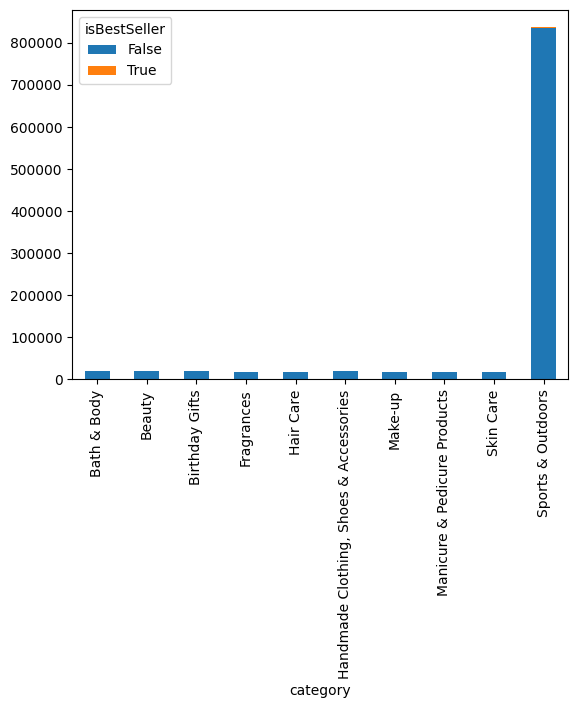

In [21]:
tabla_top.plot(kind="bar", stacked=True)

### Parte 2: Explorando precios y calificaciones de productos en diferentes categorías y marcas
Objetivo : Investigar cómo las diferentes categorías de productos influyen en los precios de los productos.

##### 0. Paso preliminar: Eliminar los valores atípicos en los precios de los productos.

- Para ello, podemos usar el método del rango intercuartílico (IQR). Los productos con precios inferiores al primer cuartil menos 1,5 veces el IQR o superiores al tercer cuartil más 1,5 veces el IQR se considerarán valores atípicos y se eliminarán del conjunto de datos. Los siguientes pasos se realizarán con el dataframe sin valores atípicos.

Sugerencia: puedes consultar la última sección de Comprobación de comprensión al final de la lección Análisis bivariado EDA para obtener una pista sobre cómo hacerlo.

In [22]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IRQ = Q3 - Q1

In [24]:
limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

limite_inferior, limite_superior

(np.float64(-44.01), np.float64(99.99000000000001))

Se eliminaron los valores atípicos del precio utilizando el método del rango intercuartílico (IQR). Los valores que estaban por debajo de Q1 − 1.5×IQR o por encima de Q3 + 1.5×IQR fueron considerados atípicos y excluidos del análisis.

In [25]:
df_sin_outliers = df[(df['price'] >= limite_inferior) & (df['price'] <= limite_superior)]

# Ver cuántos datos eliminamos
print("Tamaño original:", len(df))
print("Tamaño sin outliers:", len(df_sin_outliers))
print("Outliers eliminados:", len(df) - len(df_sin_outliers))

Tamaño original: 2443651
Tamaño sin outliers: 2115963
Outliers eliminados: 327688


In [26]:
df = df_sin_outliers

In [27]:
df_sin_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Esto nos permite trabajar con un dataset más representativo y reducir el impacto de valores extremos en los resultados.

##### 1. Diagramas de violín :

Utilice un diagrama de violín para visualizar la distribución priceentre los diferentes productos categories. Filtre las 20 categorías principales según el recuento para una mejor visualización.
¿Qué categoría de producto suele tener el precio medio más alto? No filtre aquí por categorías principales.

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

In [29]:
top20_categories = df_sin_outliers['category'].value_counts().head(20).index
df_top20 = df_sin_outliers[df_sin_outliers['category'].isin(top20_categories)]

<Axes: xlabel='price', ylabel='category'>

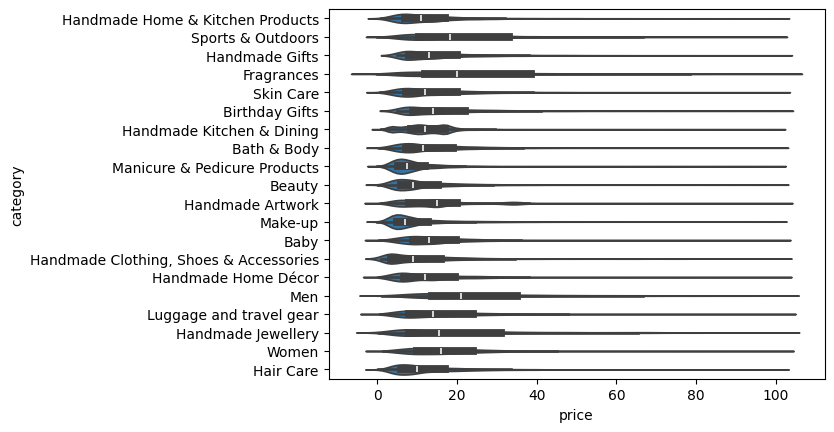

In [33]:
sns.violinplot(data=df_top20, y='category', x='price')

El gráfico de violín muestra la distribución de precios para las 20 categorías con más productos. La anchura del violín indica dónde se concentra la mayor parte de los precios, mientras que la línea interna representa la mediana.

Este gráfico permite comparar visualmente qué categorías tienden a tener precios más altos o más bajos y observar la variabilidad dentro de cada una. Categorías más anchas tienen mayor concentración de productos en ciertos rangos de precio, mientras que categorías con "colas" más largas presentan productos con precios significativamente más elevados.

In [53]:
# Agrupar por categoría y calcular el precio medio
precios_por_categoria = df_sin_outliers.groupby("category")["price"].median()

# Ordenar de mayor a menor
precios_ordenados = precios_por_categoria.sort_values(ascending=False)

# Mostrar la primera categoría (la más cara)
categoria_mas_cara = precios_ordenados.head(1)
print(categoria_mas_cara)


category
Desktop PCs    74.0
Name: price, dtype: float64


CONCLUSIÓN: La categoría con el precio medio más alto es Desktop PCs, con un precio medio de 74.00 €.
Esto indica que este tipo de producto suele tener un coste superior respecto al resto de categorías.

##### 2. Gráficos de barras :

- Crea un gráfico de barras que compare el precio promedio de los productos de las 10 categorías de productos principales (según la cantidad).
- ¿Qué categoría de producto tiene el precio promedio más alto? No filtre aquí por categorías principales.

In [37]:
top10_categorias = df_sin_outliers['category'].value_counts().head(10).index
top10_categorias

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [46]:
df_top10 = df_sin_outliers[df_sin_outliers['category'].isin(top10_categorias)]

In [49]:
precio_medio_top10 = df_top10.groupby('category')['price'].mean().sort_values()

In [50]:
precio_medio_top10

category
Manicure & Pedicure Products              10.231825
Make-up                                   10.612918
Beauty                                    12.523480
Handmade Clothing, Shoes & Accessories    12.958639
Hair Care                                 13.461408
Bath & Body                               14.678683
Skin Care                                 15.654722
Handmade Gifts                            17.395112
Birthday Gifts                            18.600195
Sports & Outdoors                         25.172065
Name: price, dtype: float64

<Axes: ylabel='category'>

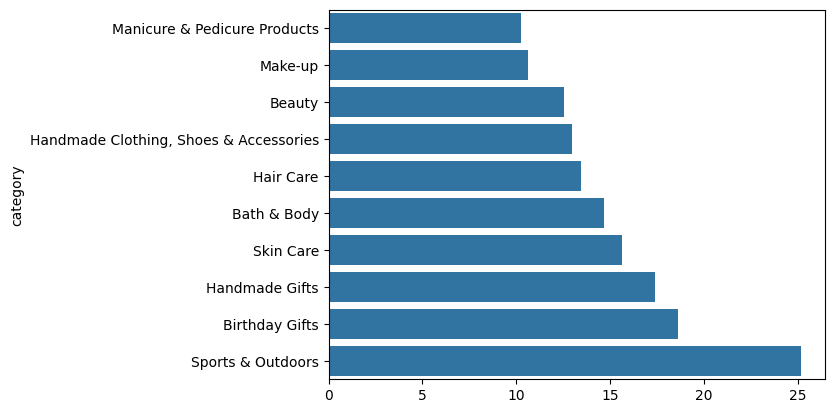

In [52]:
sns.barplot(x=precio_medio_top10.values, y=precio_medio_top10.index)

En esta gráfica se observa el precio promedio del top 10 de las mejores categorías.

In [54]:
# Agrupar por categoría y calcular el precio medio
precios_por_categoria = df_sin_outliers.groupby("category")["price"].mean()

# Ordenar de mayor a menor
precios_ordenados = precios_por_categoria.sort_values(ascending=False)

# Mostrar la primera categoría (la más cara)
categoria_mas_cara = precios_ordenados.head(1)
print(categoria_mas_cara)


category
Motherboards    68.772432
Name: price, dtype: float64


CONCLUSIÓN: La categoría con el precio medio más alto es Motherboards, con un precio promedio de 68.77€.

##### 3. Diagramas de caja :

- Visualice la distribución del producto ratingsmediante categorydiagramas de caja comparativos. Filtre las 10 categorías principales según el recuento para una mejor visualización.
- ¿Qué categoría suele recibir la valoración media más alta de los clientes? No filtre aquí por categorías principales.

In [57]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [56]:
top10_categorias = df_sin_outliers['category'].value_counts().head(10).index

df_top10 = df_sin_outliers[df_sin_outliers['category'].isin(top10_categorias)]

<Axes: xlabel='stars', ylabel='category'>

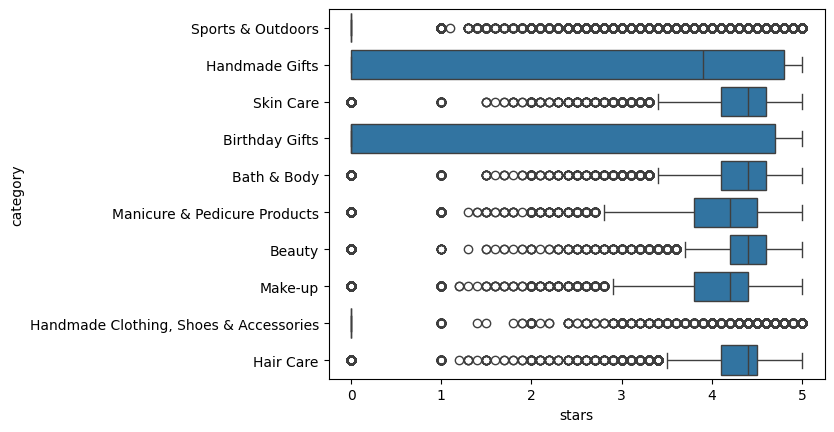

In [59]:
sns.boxplot(data=df_top10, x='stars', y='category')

In [64]:
stars_promedio = df_sin_outliers.groupby('category')['stars'].mean()

categoria_mejor_stars = stars_promedio.sort_values(ascending=False).head(1)
print(categoria_mejor_stars)

category
Luxury Food & Drink    4.54414
Name: stars, dtype: float64


La categoría que suele recibir la valoración media más alta de los clientes es Luxury Food & Drink es de 4,5.

### Parte 3: Investigación de la interacción entre los precios y las calificaciones de los productos
Objetivo : Analizar cómo starsse correlacionan las calificaciones de los productos ( ) con los precios de los mismos.

##### 1. Coeficientes de correlación :

- Calcula el coeficiente de correlación entre price y stars.
- ¿Existe una correlación significativa entre el precio del producto y su calificación?

In [65]:
correlation = df_sin_outliers['price'].corr(df['stars'])
correlation

np.float64(-0.07767299878181444)

Esto quiero decir que tiene una correlación negatia extremadamento débil. No existe una relación lineal significativa entre el precio y la valoración.

Los productos más caros no tienden a tener mejores valoraciones, ni peores. El precio prácticamente no influye en el rating de los clientes.

##### 3. Visualizaciones :

- Utilice un diagrama de dispersión para visualizar la relación entre la calificación del producto y el precio. ¿Qué patrones puede observar?
- Utilice un mapa de calor de correlación para visualizar las correlaciones entre todas las variables numéricas.
- Analice si los precios de los productos suelen seguir una distribución normal utilizando un gráfico QQ.


<Axes: xlabel='price', ylabel='stars'>

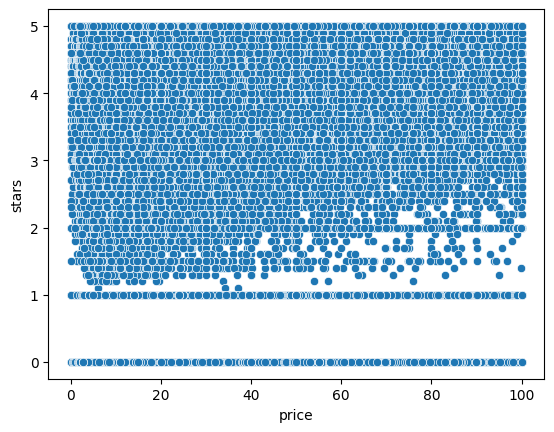

In [68]:
sns.scatterplot(data=df_sin_outliers, x='price', y='stars')

Al no tener una relación fuerte, se puede ver en el gráfico que hay diferentes valoraciones, en el que el precio no influye.

<Axes: >

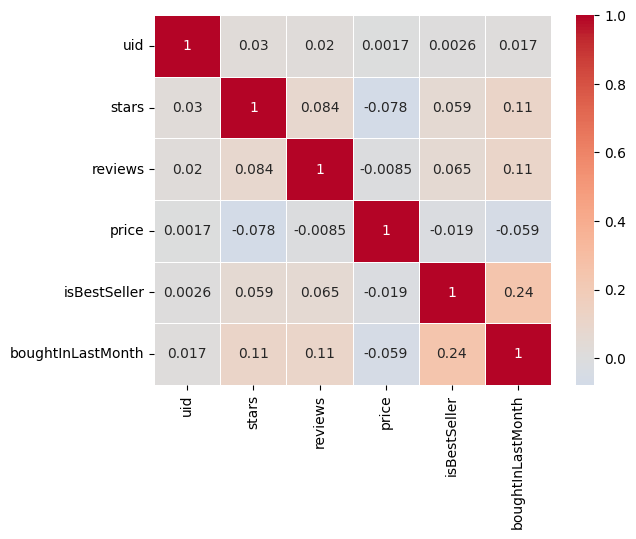

In [75]:
corr = df_sin_outliers.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,        # fuerza a centrar el color en 0
    linewidths=0.5
)

Todas las correlaciones da lugar a un valor muy cercana al 0, lo que quiere decir que las relaciones son muy débiles y que no dependen unas de otras.

((array([-4.97420488, -4.79954158, -4.70525502, ...,  4.70525502,
          4.79954158,  4.97420488], shape=(2115963,)),
  array([ 0.  ,  0.  ,  0.  , ..., 99.99, 99.99, 99.99], shape=(2115963,))),
 (np.float64(18.50452591674645),
  np.float64(23.408269686190174),
  np.float64(0.9020702992645425)))

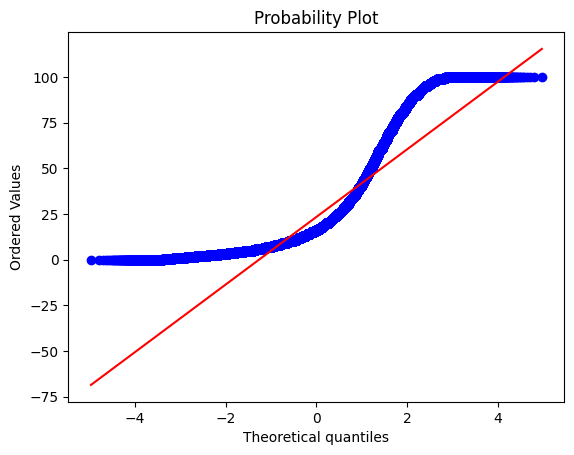

In [77]:
import scipy.stats as stats

stats.probplot(df_sin_outliers['price'], dist="norm", plot=plt)

No tiene una distribución normal. 